In [0]:
%%capture
!pip install seaborn
%restart_python

In [0]:
from pyspark.sql import functions as F
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

file_path = "/Volumes/workspace/default/health_data_volume/cleaned_base_cdi"
df = spark.read.parquet(file_path)

# --- Configuration ---
SELECTED_METRICS = [
    {
        "col": "Alcohol_Overall_Overall",
        "question": None,  
        "alias": "alcohol_rate",
        "short_label": "Alcohol Use (%)",
        "axis_label": "Mean Crude Prevalence of Alcohol Indicators (%)",
    },
    {
        "col": "Diabetes_Overall_Overall",
        "question": None,
        "alias": "diabetes_rate",
        "short_label": "Diabetes (%)",
        "axis_label": "Mean Crude Prevalence of Diabetes Indicators (%)",
    },
    {
        "col": "Mental_Health_Overall_Overall",
        "question": None,
        "alias": "mental_health_rate",
        "short_label": "Mental Health (%)",
        "axis_label": "Mean Crude Prevalence of Mental Health Indicators (%)",
    },
    {
        "col": "Immunization_Overall_Overall",
        "question": None,
        "alias": "immunization_rate",
        "short_label": "Immunization (%)",
        "axis_label": "Mean Crude Prevalence of Immunization Indicators (%)",
    },
]
VALUE_TYPE_FILTER = "Crude Prevalence"
# -------------------------------------------------------------

selected_cols = [m["col"] for m in SELECTED_METRICS]
aliases = [m["alias"] for m in SELECTED_METRICS]
short_labels = [m["short_label"] for m in SELECTED_METRICS]
axis_labels = [m["axis_label"] for m in SELECTED_METRICS]

base_cols = [
    "YearStart",
    "YearEnd",
    "Question",
    "LocationDesc",
    "DataValueType",
    "DataValueUnit",
]
subset = df.select(*base_cols, *selected_cols)

# Filter to Crude Prevalence
if VALUE_TYPE_FILTER and "DataValueType" in df.columns:
    if subset.filter(F.col("DataValueType") == VALUE_TYPE_FILTER).limit(1).count() > 0:
        subset = subset.filter(F.col("DataValueType") == VALUE_TYPE_FILTER)

# Print exact Questions included under each column
for m in SELECTED_METRICS:
    q_df = subset.filter(F.col(m["col"]).isNotNull())
    if m["question"]:
        q_df = q_df.filter(F.col("Question") == m["question"])
    distinct_states = q_df.select("LocationDesc").distinct().count()
    print(f"\n=== {m['col']} ({distinct_states} distinct states non-null) ===")
    q_df.groupBy("Question").count().orderBy(F.desc("count")).show(truncate=False)




=== Alcohol_Overall_Overall (50 distinct states non-null) ===
+----------------------------------------------------+-----+
|Question                                            |count|
+----------------------------------------------------+-----+
|Binge drinking prevalence among adults              |99   |
|Alcohol use among high school students              |44   |
|Binge drinking prevalence among high school students|42   |
+----------------------------------------------------+-----+


=== Diabetes_Overall_Overall (50 distinct states non-null) ===
+---------------------------------------------------------+-----+
|Question                                                 |count|
+---------------------------------------------------------+-----+
|Diabetes among adults                                    |98   |
|Gestational diabetes among women with a recent live birth|80   |
+---------------------------------------------------------+-----+


=== Mental_Health_Overall_Overall (50 distinct 

In [0]:
# Aggregate state-level averages (2016-2020) and join
full_df = None
for m in SELECTED_METRICS:
    q_df = subset.filter(F.col(m["col"]).isNotNull())
    if m["question"]:
        q_df = q_df.filter(F.col("Question") == m["question"])
    metric_df = (
        q_df.groupBy("LocationDesc")
        .agg(F.avg(F.col(m["col"]).cast("double")).alias(m["alias"]))
    )
    full_df = metric_df if full_df is None else full_df.join(metric_df, on="LocationDesc", how="outer")

# Trigger a Spark action (this generates a Spark Job & DAG you can screenshot)
print("\nNull counts per state-level metric:")
full_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in full_df.columns]).show()

print("\nSummary statistics across U.S. states:")
full_df.select(*aliases).summary().show()




Null counts per state-level metric:
+------------+------------+-------------+------------------+-----------------+
|LocationDesc|alcohol_rate|diabetes_rate|mental_health_rate|immunization_rate|
+------------+------------+-------------+------------------+-----------------+
|           0|           0|            0|                 0|                0|
+------------+------------+-------------+------------------+-----------------+


Summary statistics across U.S. states:
+-------+------------------+------------------+------------------+------------------+
|summary|      alcohol_rate|     diabetes_rate|mental_health_rate| immunization_rate|
+-------+------------------+------------------+------------------+------------------+
|  count|                50|                50|                50|                50|
|   mean|17.603166666666663|10.805500000000002|15.907266666666665| 48.67441428571429|
| stddev|2.5315161368727566| 1.388520528249264|2.4141053694265038| 3.496024713913153|
|    min|  

In [0]:
# Convert to Pandas for Outlier Inspection & Visualizations
pdf = full_df.toPandas()

# Print 1.5 * IQR outliers
for col_name in aliases:
    q1 = pdf[col_name].quantile(0.25)
    q3 = pdf[col_name].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = pdf[(pdf[col_name] < lower) | (pdf[col_name] > upper)][["LocationDesc", col_name]]
    print(f"Outliers for {col_name} [{lower:.2f}, {upper:.2f}]:")
    print(outliers.to_string(index=False) if not outliers.empty else "None", "\n")

sns.set_theme(style="darkgrid", palette="muted")

Outliers for alcohol_rate [11.69, 23.39]:
LocationDesc  alcohol_rate
   Wisconsin     24.833333
        Utah      9.200000 

Outliers for diabetes_rate [7.87, 13.97]:
LocationDesc  diabetes_rate
        Utah            7.7
    Colorado            7.8
     Wyoming            7.3 

Outliers for mental_health_rate [9.30, 22.09]:
None 

Outliers for immunization_rate [38.37, 59.74]:
None 



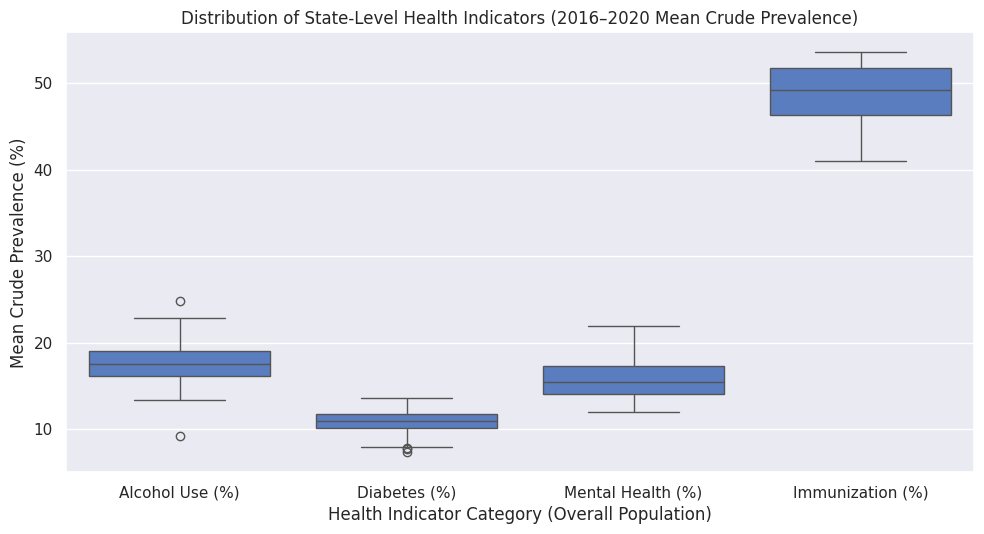

In [0]:
# Side-by-side box plots
long_df = pdf[aliases].melt(
    value_vars=aliases,
    var_name="metric",
    value_name="rate",
).dropna(subset=["rate"])

plt.figure(figsize=(10, 5.5))
ax = sns.boxplot(data=long_df, x="metric", y="rate")
ax.set_xticks(range(len(aliases)))
ax.set_xticklabels(short_labels)
plt.title("Distribution of State-Level Health Indicators (2016–2020 Mean Crude Prevalence)")
plt.xlabel("Health Indicator Category (Overall Population)")
plt.ylabel("Mean Crude Prevalence (%)")
plt.tight_layout()
plt.show()



R-squared (alcohol_rate vs diabetes_rate): 0.0558 | p-value: 9.8779e-02


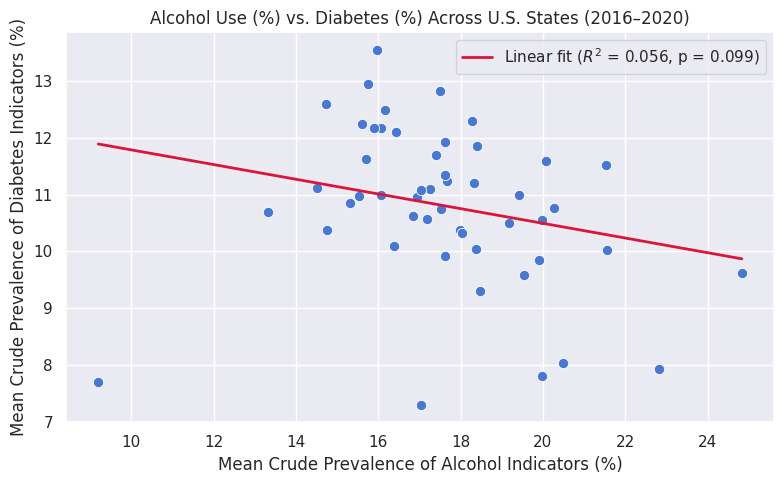

R-squared (alcohol_rate vs mental_health_rate): 0.0435 | p-value: 1.4590e-01


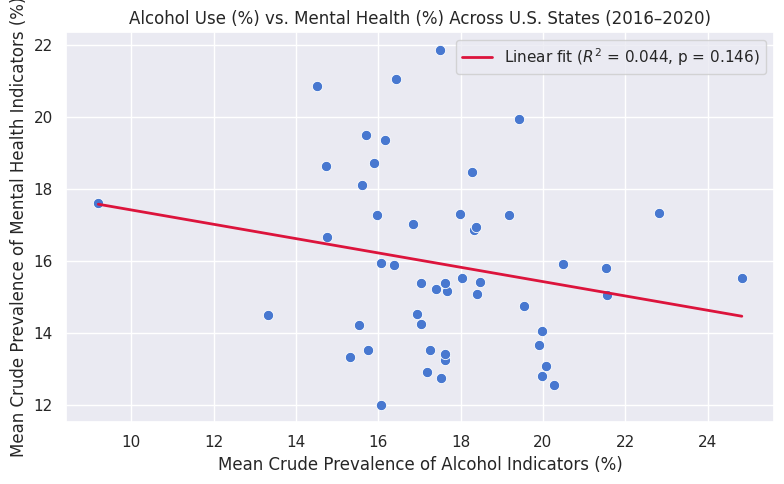

R-squared (alcohol_rate vs immunization_rate): 0.0387 | p-value: 1.7077e-01


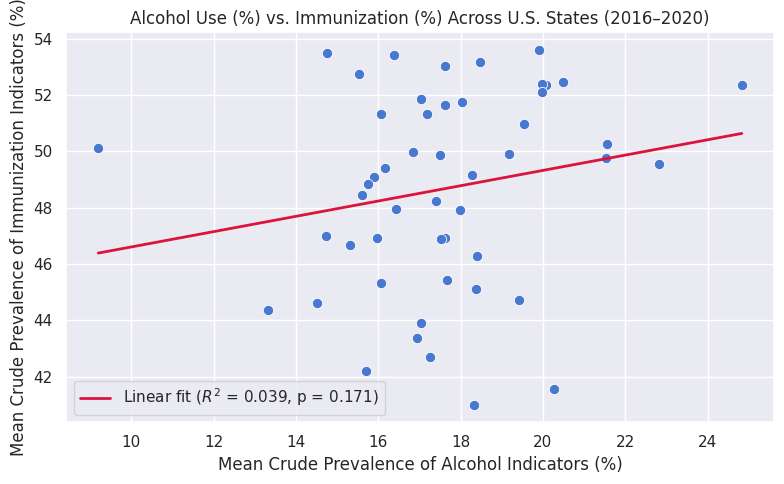

R-squared (diabetes_rate vs mental_health_rate): 0.0471 | p-value: 1.2992e-01


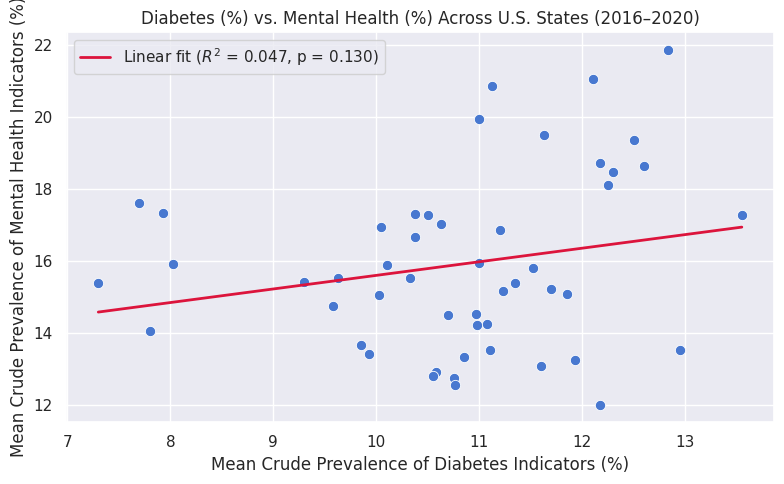

R-squared (diabetes_rate vs immunization_rate): 0.0663 | p-value: 7.1001e-02


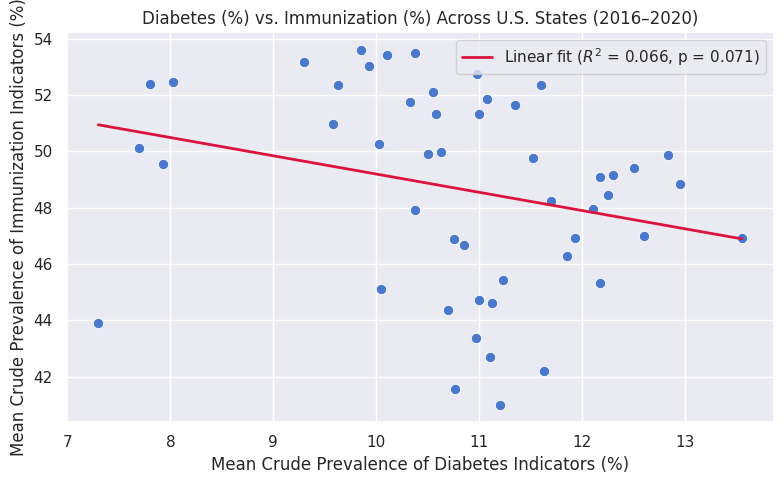

R-squared (mental_health_rate vs immunization_rate): 0.0166 | p-value: 3.7231e-01


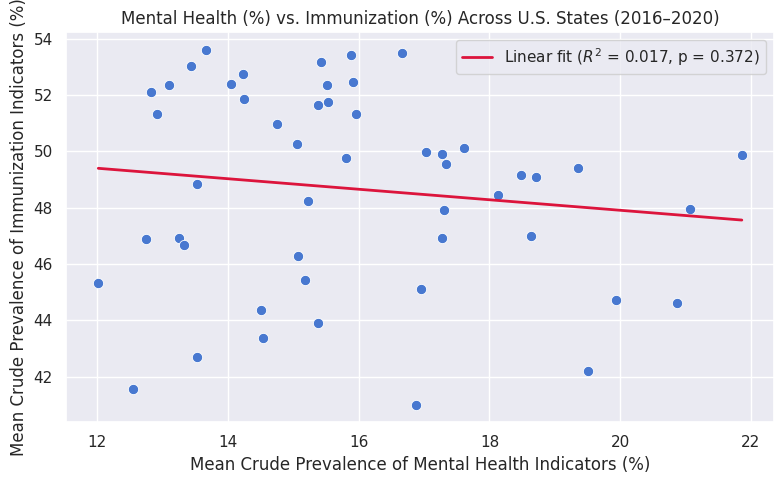

In [0]:
# Pairwise scatter plots with descriptive axis labels and linear regression lines
for i in range(len(aliases)):
    for j in range(i + 1, len(aliases)):
        x_col, y_col = aliases[i], aliases[j]
        x_ax_lbl, y_ax_lbl = axis_labels[i], axis_labels[j]
        x_short, y_short = short_labels[i].replace("\n", " "), short_labels[j].replace("\n", " ")

        pair_df = pdf[[x_col, y_col]].dropna()
        if len(pair_df) < 2:
            continue

        res = stats.linregress(pair_df[x_col], pair_df[y_col])
        r_squared = res.rvalue ** 2
        x_line = np.linspace(pair_df[x_col].min(), pair_df[x_col].max(), 200)
        y_line = res.slope * x_line + res.intercept

        print(f"R-squared ({x_col} vs {y_col}): {r_squared:.4f} | p-value: {res.pvalue:.4e}")

        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=pair_df, x=x_col, y=y_col, s=55)
        plt.plot(
            x_line,
            y_line,
            color="crimson",
            linewidth=2,
            label=f"Linear fit ($R^2$ = {r_squared:.3f}, p = {res.pvalue:.3f})",
        )
        plt.title(f"{x_short} vs. {y_short} Across U.S. States (2016–2020)")
        plt.xlabel(x_ax_lbl)
        plt.ylabel(y_ax_lbl)
        plt.legend()
        plt.tight_layout()
        plt.show()